In [19]:
import os

In [20]:
import os
import json
import numpy as np
import cv2
import pandas as pd
import tensorflow as tf
from tensorflow.keras.models import load_model
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns


In [21]:
# Paths - handle both script and notebook execution
try:
    # When running as a script
    script_dir = os.path.dirname(os.path.abspath(__file__))
except NameError:
    # When running in a notebook
    script_dir = os.getcwd()

BASE_DIR = os.path.join(script_dir, "..", "data_set_generator_for_cnns_only", "data_set")
TRAIN_IMG_DIR = os.path.join(BASE_DIR, "train")
VALID_IMG_DIR = os.path.join(BASE_DIR, "valid")
TEST_IMG_DIR = os.path.join(BASE_DIR, "test")
TRAIN_CSV = os.path.join(BASE_DIR, "train.csv")
VALID_CSV = os.path.join(BASE_DIR, "valid.csv")
TEST_CSV = os.path.join(BASE_DIR, "test.csv")

MODEL_PATH = os.path.join(script_dir, "single_digit_model_final.keras")
METRICS_PATH = os.path.join(script_dir, "runs", "eval", "exp", "metrics.json")

PLOTTING VALIDATION AND TEST CONFUSION MATRICES (COUNTS ONLY)
Loading metrics from: a:\ResearchPaper\app\internship_computer_visions_engineering\cnns_training\runs\eval\exp\confusion_matrix_metrics.json
Validation set: 200 images × 5 digits = 1000 samples
Test set: 212 images × 5 digits = 1060 samples
Saved plot to: a:\ResearchPaper\app\internship_computer_visions_engineering\cnns_training\runs\eval\exp\confusion_matrix_validation_test_counts_separate.png


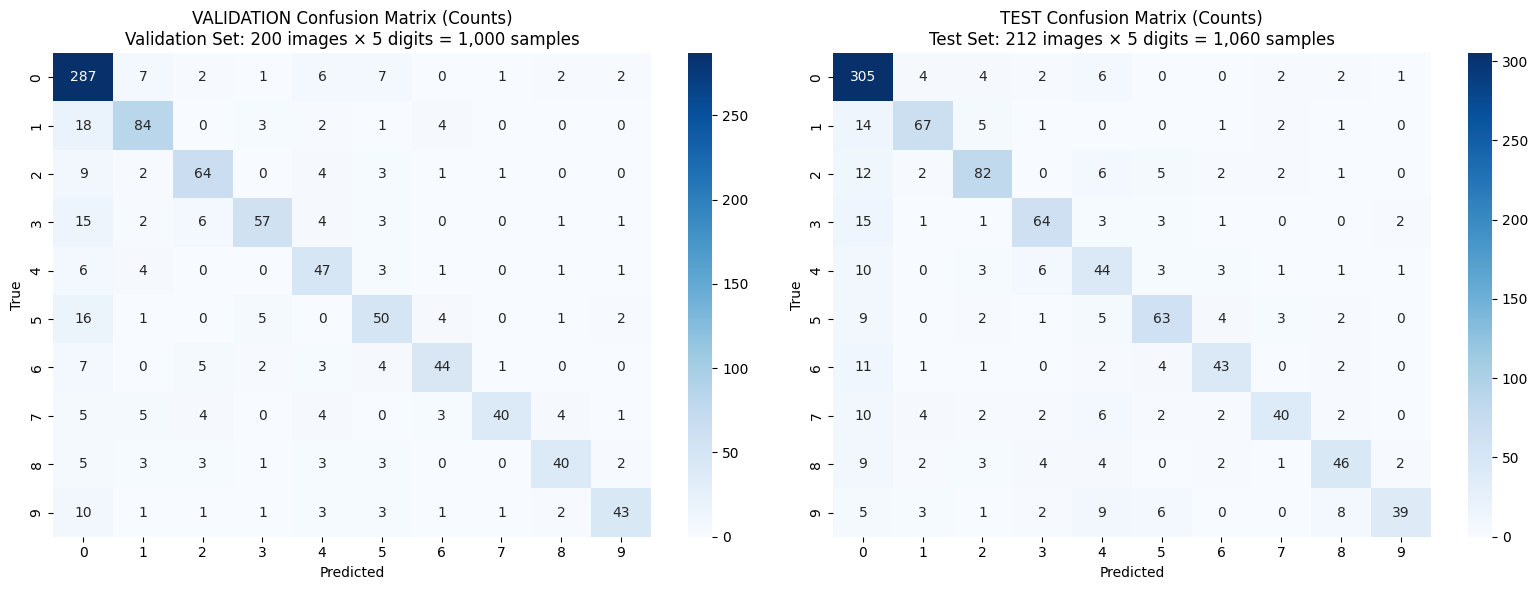


VALIDATION METRICS
Per-digit accuracy: 0.7560 (75.60%)
Exact match accuracy: 0.4950 (49.50%)
Exact matches: 99 / 200 images

TEST METRICS
Per-digit accuracy: 0.7481 (74.81%)
Exact match accuracy: 0.5189 (51.89%)
Exact matches: 110 / 212 images

VALIDATION CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0     0.7593    0.9111    0.8283       315
           1     0.7706    0.7500    0.7602       112
           2     0.7529    0.7619    0.7574        84
           3     0.8143    0.6404    0.7170        89
           4     0.6184    0.7460    0.6763        63
           5     0.6494    0.6329    0.6410        79
           6     0.7586    0.6667    0.7097        66
           7     0.9091    0.6061    0.7273        66
           8     0.7843    0.6667    0.7207        60
           9     0.8269    0.6515    0.7288        66

    accuracy                         0.7560      1000
   macro avg     0.7644    0.7033    0.7267      1000
weighted avg     

In [22]:
# Confusion matrix plotting for validation and test sets (counts only, separate graphs)
import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("=" * 70)
print("PLOTTING VALIDATION AND TEST CONFUSION MATRICES (COUNTS ONLY)")
print("=" * 70)

# Load the confusion matrix metrics
# Use current working directory for notebook compatibility
metrics_path = os.path.join(os.getcwd(), "runs", "eval", "exp", "confusion_matrix_metrics.json")
print(f"Loading metrics from: {metrics_path}")

with open(metrics_path, 'r') as f:
    metrics = json.load(f)

# Extract validation and test data
validation_data = metrics['validation']
test_data = metrics['test']
class_names = [str(i) for i in range(10)]

print(f"Validation set: {validation_data['num_images']} images × 5 digits = {validation_data['num_digit_crops']} samples")
print(f"Test set: {test_data['num_images']} images × 5 digits = {test_data['num_digit_crops']} samples")

# Create confusion matrices (counts only - NO normalized matrices)
val_conf_matrix = np.array(validation_data['confusion_matrix_counts'])
test_conf_matrix = np.array(test_data['confusion_matrix_counts'])

# Create separate plots for validation and test (side by side)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot validation counts
sns.heatmap(val_conf_matrix, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=class_names, yticklabels=class_names)
axes[0].set_title('VALIDATION Confusion Matrix (Counts)\nValidation Set: 200 images × 5 digits = 1,000 samples')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('True')

# Plot test counts
sns.heatmap(test_conf_matrix, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=class_names, yticklabels=class_names)
axes[1].set_title('TEST Confusion Matrix (Counts)\nTest Set: 212 images × 5 digits = 1,060 samples')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('True')

plt.tight_layout()

# Save the plot
output_path = os.path.join(os.getcwd(), "runs", "eval", "exp", "confusion_matrix_validation_test_counts_separate.png")
plt.savefig(output_path, dpi=150, bbox_inches='tight')
print(f"Saved plot to: {output_path}")

# Show the plot
plt.show()

# Print metrics for both sets
print("\n" + "=" * 70)
print("VALIDATION METRICS")
print("=" * 70)
print(f"Per-digit accuracy: {validation_data['per_digit_accuracy']:.4f} ({validation_data['per_digit_accuracy']*100:.2f}%)")
print(f"Exact match accuracy: {validation_data['exact_match_accuracy']:.4f} ({validation_data['exact_match_accuracy']*100:.2f}%)")
print(f"Exact matches: {validation_data['exact_matches']} / {validation_data['num_digit_crops']//5} images")

print("\n" + "=" * 70)
print("TEST METRICS")
print("=" * 70)
print(f"Per-digit accuracy: {test_data['per_digit_accuracy']:.4f} ({test_data['per_digit_accuracy']*100:.2f}%)")
print(f"Exact match accuracy: {test_data['exact_match_accuracy']:.4f} ({test_data['exact_match_accuracy']*100:.2f}%)")
print(f"Exact matches: {test_data['exact_matches']} / {test_data['num_digit_crops']//5} images")

# Show classification reports
print("\n" + "=" * 70)
print("VALIDATION CLASSIFICATION REPORT")
print("=" * 70)
print(validation_data['classification_report'])

print("\n" + "=" * 70)
print("TEST CLASSIFICATION REPORT")
print("=" * 70)
print(test_data['classification_report'])